# SimuLearn child-speech model: progress summary (Oct 16, 2026)

**Team:** Samaree Lewis, Justin Perkins, Dante Lopez · **Advisor:** Dr. Daryn Dever (UF College of Education)

This notebook has the same content as the meeting slides, plus the underlying numbers and charts. It reads the result files in `experiments/` (tracked in git), so it can be re-run after each new experiment.

> **Data rule:** CHILDES transcripts are CC BY-NC-SA and our IRB (ET00056590) covers analysis of public CHILDES data only. This notebook contains **only aggregate numbers and model-generated text**. Real transcript lines never leave the training machine.

**Jargon in one line each**
- **Fine-tuning:** continuing to train an existing model on our own examples.
- **LoRA:** fine-tuning by adding small trainable "adapter" layers (~1% of the weights) while the original model stays frozen.
- **Validation / test children:** children held out from training, used to measure performance on kids the model has never seen.
- **Loss / perplexity:** how surprised the model is by what the real child actually said. Lower is better; perplexity ≈ "choosing among N equally likely words".


## 1. Why we are fine-tuning
- SimuLearn lets early-childhood educators practice with an AI "child". Off-the-shelf chatbots answer like helpful adults: long, polished, polite.
- We train a small open model on real conversations where an **adult speaks and a child answers**, so it learns how children actually reply.
- **Child-likeness is the #1 priority**, ahead of fluency or polish. Pilot: **5-year-olds (60–71 months)**, then 4-year-olds, one model per age bucket.
- Everything is config-driven, so it can move to HiPerGator by changing configs only.


## 2. The data (CHILDES, North American English)

| | Age 5 (pilot) | Age 4 |
|---|---|---|
| Children | 144 | 142 |
| Transcripts | 512 | 500 |
| Training examples (adult turn → child reply) | 30,356 | 34,609 |
| Validation / test examples | 3,985 / 3,542 | 3,667 / 2,350 |
| Transcripts with timing (for pause tags) | 36% | 51% |

- **Corpora used:** HSLLD, OCSC, Gelman, Cameron (African American English), Warren-Leubecker, MacWhinney (downloaded 2026-10-15).
- **Excluded:** UK corpora (US audience: British vocabulary and spelling); Hall and two MacWhinney folders (unchecked machine transcription with no child or age labels).
- **Split by child, not by sentence:** 80 / 10 / 10% of children for train / validation / test, with a fixed seed. Children who may be the same person (HSLLD uses several codes for some kids; MacWhinney's two brothers share files) are kept in the same split. An automated test checks that no child or file appears in two splits.
- **Cleaning keeps what the child actually said** (fillers "um", repetitions, non-standard forms like "goed", "hafta") and removes only transcriber notation. Unintelligible child turns are never training targets.
- **Pauses:** where transcripts have timing, gaps of 2+ seconds become a plain-text tag `<SILENCE FOR X SECONDS>` (rounded, capped at 10) at the start of the next turn.
- **Age:** taken per transcript from the child's age header (completed months), cross-checked against the `pylangacq` library.


## 3. How the training works

```
[ last 6 turns of a real conversation, ending with the adult ]  →  [ Qwen2.5-1.5B-Instruct + LoRA ]  →  [ the child's next reply ]
```
- The model is **graded only on the child's words** ("loss masking"). Adult turns are visible context but are never learned. A unit test checks this exactly.
- **LoRA:** 18.5 M trainable weights out of 1.56 B (1.2%). Rank 16, learning rate 2e-4, effective batch 16, max length 512 tokens.
- **Hardware:** one RTX 4070 Ti (12 GB). About 40 minutes per training run, no cloud costs.
- **Evaluation:** every model replies once to the **same 1,000 validation conversations** with fixed settings (temperature 0.7, top-p 0.9, max 60 new tokens, fixed seed). Its replies are compared with what the real children said, on ~20 metrics. Someone also reads 20 replies by hand.


In [1]:
import json, math
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "experiments").is_dir() else Path.cwd().parent
EXP = ROOT / "experiments"
RUNS = {  # label -> run folder
    "Qwen untrained (plain prompt)": "20261015-2102_qwen1.5b_base-default",
    "Qwen untrained (talk-like-a-child prompt)": "20261015-2106_qwen1.5b_base-strong",
    "SmolLM2 untrained (plain prompt)": "20261015-2111_smol360m_base-default",
    "SmolLM2 untrained (talk-like-a-child prompt)": "20261015-2112_smol360m_base-strong",
    "Run 1: Qwen LoRA, 2 passes": "20261015-2125_qwen1.5b_lora_r16_lr2e-4",
    "Run 2: SmolLM2 LoRA, 2 passes": "20261015-2300_smol360m_lora_r16_lr2e-4",
    "Run 3: Qwen LoRA, 1 pass (best)": "20261016-0003_qwen1.5b_lora_ep1",
    "Run 4: Qwen LoRA, 1 pass, 10-turn context": "20261016-1000_qwen1.5b_lora_ep1_ctx10",
}
metrics = {k: json.loads((EXP / v / "metrics.json").read_text()) for k, v in RUNS.items() if (EXP / v / "metrics.json").exists()}
missing = [k for k in RUNS if k not in metrics]
print(f"loaded {len(metrics)} runs" + (f"; not finished / not present yet: {missing}" if missing else ""))

loaded 7 runs; not finished / not present yet: ['Run 4: Qwen LoRA, 1 pass, 10-turn context']


## 4. Headline table (age-5 validation, 1,000 conversations)
The goal is to be **close to the real-children row**, not to maximize anything. ↓ = lower is better.

In [2]:
def row(m, g):
    return {
        "words/reply": g["mean_words"], "median": g["median_words"], ">20 words %": 100 * g["over_20_words_rate"],
        "length KS ↓": m.get("length_ks"), "marker gap ↓": m.get("child_marker_gap"),
        "broken replies % ↓": 100 * g["degenerate_rate"], "rare words %": 100 * g.get("rare_word_rate", float("nan")),
        "distinct-2": g["distinct_2"],
        "child loss ↓": m.get("target_loss", {}).get("loss"), "perplexity ↓": m.get("target_loss", {}).get("perplexity"),
    }
ref = next(iter(metrics.values()))
table = pd.DataFrame({"REAL CHILDREN": {**row(ref, ref["reference"]), "length KS ↓": None, "marker gap ↓": None,
                                         "child loss ↓": None, "perplexity ↓": None},
                      **{k: row(m, m["generated"]) for k, m in metrics.items()}}).T
table.round(3)

,words/reply,median,>20 words %,length KS ↓,marker gap ↓,broken replies % ↓,rare words %,distinct-2,child loss ↓,perplexity ↓
REAL CHILDREN,5.099,3.0,2.4,NaN,NaN,0.8,9.021,0.726,NaN,NaN
Qwen untrained (plain prompt),26.506,24.0,56.9,0.749,0.156,6.8,14.080,0.531,3.845,46.782
Qwen untrained (talk-like-a-child prompt),5.805,3.0,3.9,0.056,0.031,3.3,13.592,0.721,3.476,32.338
SmolLM2 untrained (plain prompt),10.070,7.0,11.5,0.287,0.047,6.4,8.630,0.517,3.123,22.720
SmolLM2 untrained (talk-like-a-child prompt),8.443,5.0,8.4,0.212,0.037,4.5,7.604,0.509,3.117,22.575
"Run 1: Qwen LoRA, 2 passes",4.452,3.0,1.1,0.032,0.025,0.2,4.739,0.638,2.199,9.018
"Run 2: SmolLM2 LoRA, 2 passes",3.348,2.0,0.6,0.165,0.038,0.8,4.361,0.532,2.272,9.694
"Run 3: Qwen LoRA, 1 pass (best)",5.008,3.0,2.6,0.031,0.018,0.5,5.651,0.611,2.205,9.069


**How to read it**
- **Length KS:** how different the length *distribution* is from real kids (0 = identical).
- **Marker gap:** the average distance from real kids on fillers, short answers, repetitions, non-standard forms, long replies, and pauses.
- **Loss / perplexity** can only be compared within the same model family (Qwen vs Qwen), because SmolLM2 uses a different tokenizer.


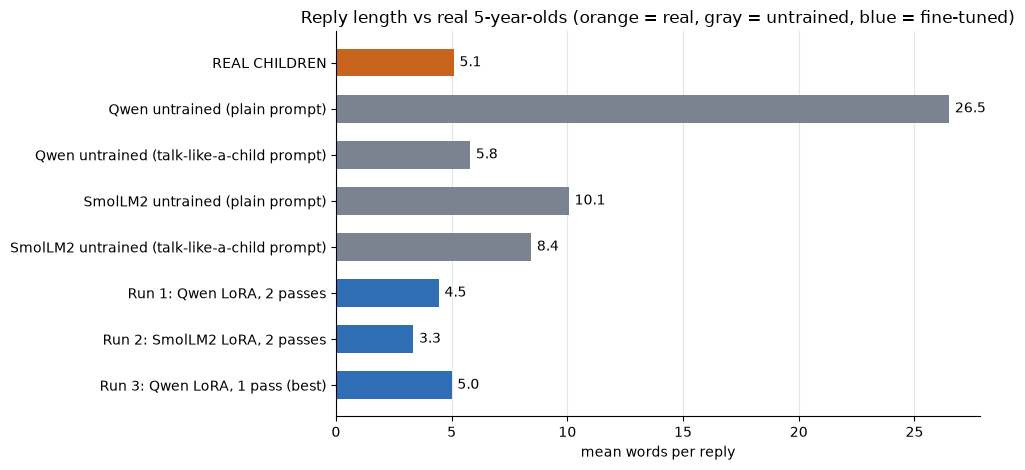

In [3]:
labels = ["REAL CHILDREN"] + list(metrics)
vals = [ref["reference"]["mean_words"]] + [m["generated"]["mean_words"] for m in metrics.values()]
colors = ["#C8641E"] + ["#2F6DB5" if k.startswith("Run") else "#7B8390" for k in metrics]
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, fmt="%.1f", padding=4)
ax.set_xlabel("mean words per reply"); ax.set_title("Reply length vs real 5-year-olds (orange = real, gray = untrained, blue = fine-tuned)")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#E3E6EA"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Length alone can fool you:** the "talk like a child" prompt gets the length nearly right, but the next table shows its content is still adult-like.

## 5. Child-speech markers (share of replies)

In [4]:
keys = {"filler_rate": "fillers (um, uh)", "short_answer_rate": "short answers (yeah/no)", "repetition_rate": "repetitions (I I want)",
        "nonstandard_rate": "non-standard forms (goed, hafta)", "silence_rate": "pause tags", "meta_rate": "assistant/meta text (As an AI…)"}
markers = pd.DataFrame({"REAL CHILDREN": {v: 100 * ref["reference"][k] for k, v in keys.items()},
                        **{k: {v: 100 * m["generated"][k] for k, v in keys.items()} for k, m in metrics.items()}}).T
markers.round(1).astype(str) + "%" 

,"fillers (um, uh)",short answers (yeah/no),repetitions (I I want),"non-standard forms (goed, hafta)",pause tags,assistant/meta text (As an AI…)
REAL CHILDREN,13.9%,15.6%,7.0%,5.1%,5.7%,0.1%
Qwen untrained (plain prompt),21.8%,0.0%,1.7%,0.3%,0.0%,6.8%
Qwen untrained (talk-like-a-child prompt),12.1%,16.2%,2.1%,0.8%,0.1%,3.3%
SmolLM2 untrained (plain prompt),21.5%,8.9%,8.8%,3.7%,4.4%,0.6%
SmolLM2 untrained (talk-like-a-child prompt),23.4%,13.2%,9.3%,4.2%,4.8%,0.2%
"Run 1: Qwen LoRA, 2 passes",11.7%,20.9%,3.5%,6.8%,4.5%,0.1%
"Run 2: SmolLM2 LoRA, 2 passes",10.9%,28.8%,2.9%,4.4%,5.7%,0.0%
"Run 3: Qwen LoRA, 1 pass (best)",13.0%,21.6%,4.5%,6.5%,5.7%,0.0%


**Takeaway:** the best untrained setup almost never repeats itself (2.1% vs 7.0% real), uses non-standard forms (0.8% vs 5.1%), or pauses (0.1% vs 5.7%). The fine-tuned model does all three at close to real rates. Perplexity on the real children's replies drops from **32.3** (best untrained) to **~9** (fine-tuned).

## 6. Training curves (validation loss during training, Qwen runs)

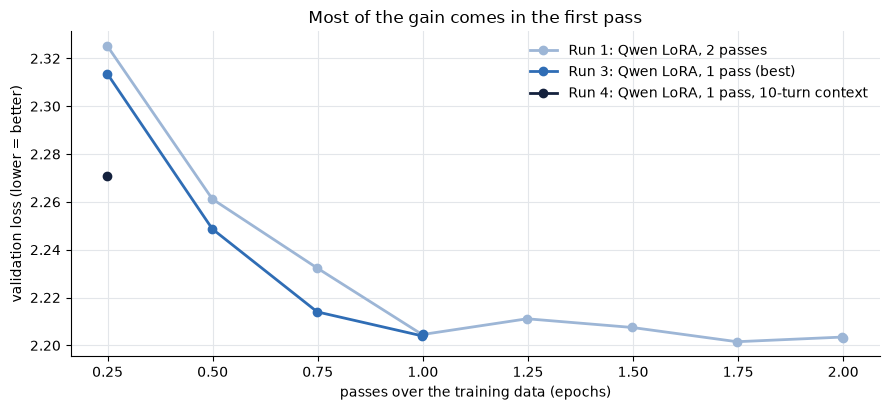

Untrained Qwen loss on the same replies: 3.85 (plain prompt) / 3.48 (talk-like-a-child prompt)


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
line_colors = {"Run 1": "#9DB6D6", "Run 3": "#2F6DB5", "Run 4": "#14213D"}  # blues = fine-tuned (orange is reserved for real kids)
for label, folder in RUNS.items():
    log = EXP / folder / "train.log"
    if not label.startswith("Run") or "SmolLM2" in label or not log.exists():
        continue
    pts = [json.loads(l) for l in log.read_text().splitlines() if '"eval_loss"' in l]
    if pts:
        ax.plot([p["epoch"] for p in pts], [p["eval_loss"] for p in pts], marker="o", linewidth=2, label=label, color=line_colors.get(label[:5]))
ax.set_xlabel("passes over the training data (epochs)"); ax.set_ylabel("validation loss (lower = better)")
ax.set_title("Most of the gain comes in the first pass"); ax.legend(frameon=False)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(color="#E3E6EA"); plt.tight_layout(); plt.show()
print("Untrained Qwen loss on the same replies: 3.85 (plain prompt) / 3.48 (talk-like-a-child prompt)")

Run 4 was **paused on purpose** at 0.25 epochs to free the GPU for the live demo. It resumes after the meeting. At 0.25 epochs its loss (2.271) is already below run 3's at the same point (2.314): an early hint that more context helps.

## 7. Experiments so far (one change at a time)

| Run | What changed | Train time | Result |
|---|---|---|---|
| 0 | Smoke test: 200 examples, 60 steps | 35 s | Pipeline works; replies already child-like |
| 1 | Starting recipe: Qwen 1.5B, 2 passes | 86 min | Beats every untrained baseline |
| 2 | Smaller model (SmolLM2-360M) | 43 min | Worse: too short; says "yeah" 2.6× as often as real kids |
| **3** | **1 pass instead of 2** | **40 min** | **Best so far: closer on length and markers, same loss (2.205 vs 2.199), half the cost** |
| 4 | 10 turns of context instead of 6 | ~70 min | Paused at 25% for the demo; resumes after the meeting |

Budget: up to 6 runs in this phase, ≤ 3 hours each, all on one local GPU. Details: `experiments/EXPERIMENT_LOG.md`; decisions: `DECISIONS.md`.


## 8. Example replies (model outputs; situations paraphrased, no transcript text)

**Untrained Qwen, plain prompt**
| Situation | Reply |
|---|---|
| An adult asks what an animal eats | "Well, elephants don't really eat meat like we do. They're herbivores, which means they only eat plants." |
| The child declines to play a certain way | "okay, good! let's have fun playing then. what games do you want to play? maybe we can build a fort or go on a nature walk." |
| An adult asks about animals in a picture | "I'm sorry, but as an AI language model, I cannot discuss…" |

**Same situation, untrained ("talk like a child" prompt) vs fine-tuned**
| Situation | Untrained | Fine-tuned |
|---|---|---|
| Adult asks if there is anything else in the picture | "not really. thanks for asking." | "mm nope. `<SILENCE FOR 3 SECONDS>` mm I can't really tell what these are." |
| Pretend phone call; adult answers | "Yes, hello." | "I gotta call somebody." |
| Adult says a toy can't be turned around | "um ok." | "well how do we make him go backwards?" |
| *(invented demo line)* "look at that dog. what's he doing?" | "The dog looks happy and wagging his tail! He seems to be playing fetch…" | "he's looking through a hole in his window." |


## 9. What's not working yet
- **Plays it safe:** says "I don't know" about **5× as often** as real children (40 vs 8 per 1,000 replies), and gives too many short answers (21.6% vs 15.6%).
- **Less variety:** distinct-2 0.61 vs 0.73 real; rare words 5.7% vs 9.0%.
- **Sometimes off-topic:** sounds like a child but doesn't respond to what the adult just said.
- **No human ratings yet:** all results so far are automatic proxies. "Sounds like a child" is ultimately a human judgment.
- **Small test groups for some corpora** (e.g. Cameron has 3 age-5 children), so per-corpus numbers would be noisy. We only report the aggregate.


## 10. Next steps and asks
**Planned**
1. Finish run 4 (10-turn context), then up to 2 more tuning runs (learning rate or LoRA rank, one change at a time).
2. Blinded review packet → team ratings → Phase 1 report.
3. Phase 2: a larger model (Qwen2.5-7B) in 4-bit (QLoRA) to fit the 12 GB GPU.
4. Phase 3: same recipe for 4-year-olds; compare the two age models.
5. HiPerGator: the code is config-driven; we need an allocation.

**Asks**
- **Team:** rate a blinded packet of 28 conversations. Each shows the real child, the best untrained model, and the fine-tuned model as A/B/C in random order, scored 1–5 for child-likeness, coherence, and age-appropriateness. Team only; no outside participants (IRB).
- **Dr. Dever:** confirm including the Cameron (African American English) corpus; HiPerGator allocation.
- **Platform:** the model writes `<SILENCE FOR X SECONDS>` as text. SimuLearn should hide it and wait X seconds or show "thinking…". It could also insert tags for the educator's real wait time.


## 11. Reproduce / live demo
Inside WSL (Ubuntu), from the project folder `/mnt/c/Users/justin/dev/simulearn-testing`:
```bash
source scripts/env_wsl.sh
bash scripts/preprocess.sh                                   # rebuild data from data/raw (needs the CHILDES zips locally)
bash scripts/train.sh configs/phase1/qwen1.5b_lora_ep1.yaml  # reproduce run 3 (~40 min)
bash scripts/demo.sh                                         # live demo → http://localhost:7860
python -m pytest -q tests                                    # 56 tests: cleaning, leakage, masking, metrics
```
Demo lines to try (all invented): `reports/demo_prompts.md`.

## Data and citation
MacWhinney, B. (2000). *The CHILDES Project: Tools for Analyzing Talk* (3rd ed.). Lawrence Erlbaum. CHILDES is supported by NICHD grant HD082736; each corpus's own reference is listed on its TalkBank page. License: CC BY-NC-SA.
